# Transfer learning

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://githubtocolab.com/EnriqueVilchezL/machine-learning/blob/main/book/06-deep-learning/transfer-learning/transfer-learning-notebook.ipynb)

Companion notebook for the *Transfer learning* slides. Each idea is written first by hand
with NumPy and then with the scikit-learn tool that does the same job.

**Data:** the handwritten Digits (1797 images of 8x8 pixels). The source task is naming the digit
(0 to 9) on one half of the images; the target task, on the other half, is telling whether a digit has a closed loop (0, 6, 8, 9).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import minimize_scalar
from scipy.special import expit
from sklearn.datasets import load_digits
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPClassifier

RANDOM_STATE = 42
HIDDEN = 64
FEW_PER_CLASS = 5
N_T_CHOICES = [3, 5, 10, 25, 50]
DRAWS = 5
FT_LEARNING_RATE = 0.05
FT_EPOCHS = 100

X, y = load_digits(return_X_y=True)
X = X / 16
X_source, X_target, y_source, digit_target = train_test_split(X, y, test_size=0.5, random_state=RANDOM_STATE, stratify=y)
y_target = np.isin(digit_target, [0, 6, 8, 9]).astype(int)
XT_train, XT_test, yT_train, yT_test = train_test_split(X_target, y_target, test_size=0.5,
                                                        random_state=RANDOM_STATE, stratify=y_target)


def few_labels(per_class: int, seed: int) -> np.ndarray:
    """Indices of `per_class` random target training examples of each class."""
    rng = np.random.default_rng(seed)
    return np.concatenate([rng.choice(np.flatnonzero(yT_train == c), per_class, replace=False) for c in (0, 1)])

## 1. Pretraining on the source task

A network with one hidden layer learns $\boldsymbol\theta_S$ on the many source images. Its forward pass is
$\hat{\mathbf{y}} = \text{softmax}\big(\mathbf{W}^{(2)} g(\mathbf{W}^{(1)}\mathbf{x} + \mathbf{b}^{(1)}) + \mathbf{b}^{(2)}\big)$ with $g$ = ReLU.

In [2]:
source_net = MLPClassifier(hidden_layer_sizes=(HIDDEN,), max_iter=1000, random_state=RANDOM_STATE).fit(X_source, y_source)
W1, b1 = source_net.coefs_[0], source_net.intercepts_[0]
W2, b2 = source_net.coefs_[1], source_net.intercepts_[1]

hidden = np.maximum(X_target @ W1 + b1, 0)
scores = hidden @ W2 + b2
proba_by_hand = np.exp(scores) / np.exp(scores).sum(axis=1, keepdims=True)
print("same result:", np.allclose(proba_by_hand, source_net.predict_proba(X_target)))

same result: True


## 2. Feature extraction: frozen body, new head

The frozen body gives the features $\boldsymbol\phi(\mathbf{x}) = g(\mathbf{W}^{(1)}\mathbf{x} + \mathbf{b}^{(1)})$.
Only a new head is trained on them, here a logistic regression with few target labels.

In [3]:
def phi(images: np.ndarray) -> np.ndarray:
    """Features from the frozen source body."""
    return np.maximum(images @ W1 + b1, 0)


rows = few_labels(FEW_PER_CLASS, RANDOM_STATE)
head = LogisticRegression(max_iter=5000).fit(phi(XT_train[rows]), yT_train[rows])

p_by_hand = expit(phi(XT_test) @ head.coef_[0] + head.intercept_[0])
print("same result:", np.allclose(p_by_hand, head.predict_proba(phi(XT_test))[:, 1]))
print(f"trainable head parameters: {head.coef_.size + head.intercept_.size}")

same result: True
trainable head parameters: 65


Always compare with the same network trained from scratch on the same few labels.

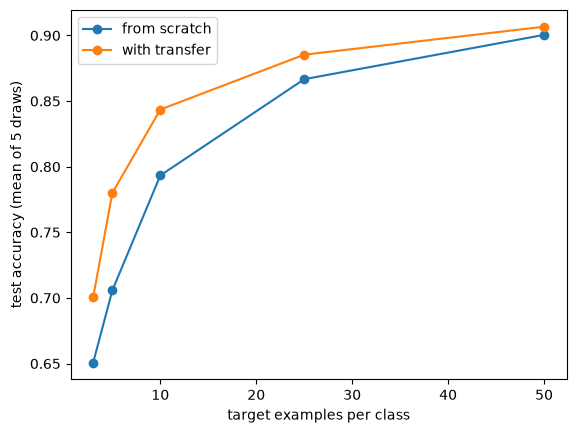

In [4]:
accuracy = {"from scratch": [], "with transfer": []}
for n_T in N_T_CHOICES:
    scratch, transfer = [], []
    for seed in range(DRAWS):
        rows = few_labels(n_T, seed)
        scratch_net = MLPClassifier(hidden_layer_sizes=(HIDDEN,), max_iter=3000, random_state=RANDOM_STATE)
        scratch.append(scratch_net.fit(XT_train[rows], yT_train[rows]).score(XT_test, yT_test))
        new_head = LogisticRegression(max_iter=5000).fit(phi(XT_train[rows]), yT_train[rows])
        transfer.append(new_head.score(phi(XT_test), yT_test))
    accuracy["from scratch"].append(np.mean(scratch))
    accuracy["with transfer"].append(np.mean(transfer))

for label, values in accuracy.items():
    plt.plot(N_T_CHOICES, values, marker="o", label=label)
plt.xlabel("target examples per class")
plt.ylabel(f"test accuracy (mean of {DRAWS} draws)")
plt.legend()
plt.show()

## 3. Fine-tuning

Fine-tuning also trains the body, starting at the source parameters, $\boldsymbol\theta^{(0)} = \boldsymbol\theta_S$,
with a small step: $\boldsymbol\theta \leftarrow \boldsymbol\theta - \alpha_{\text{ft}} \nabla J_T(\boldsymbol\theta)$.
It needs more labels than a head alone, so here we use all the target training images.
We copy the body and a new head into a fresh network; before any step it predicts exactly like the frozen model.

In [5]:
full_head = LogisticRegression(max_iter=5000).fit(phi(XT_train), yT_train)
tuned = MLPClassifier(hidden_layer_sizes=(HIDDEN,), solver="sgd", momentum=0, learning_rate_init=FT_LEARNING_RATE,
                      random_state=RANDOM_STATE)
tuned.partial_fit(XT_train, yT_train, classes=[0, 1])
tuned.coefs_ = [W1.copy(), full_head.coef_.T.copy()]
tuned.intercepts_ = [b1.copy(), full_head.intercept_.copy()]
print("same result:", np.allclose(tuned.predict_proba(XT_test), full_head.predict_proba(phi(XT_test))))

same result: True


In [6]:
print(f"before fine-tuning: test accuracy {tuned.score(XT_test, yT_test):.3f}")
for _ in range(FT_EPOCHS):
    tuned.partial_fit(XT_train, yT_train)
print(f"after {FT_EPOCHS} epochs: test accuracy {tuned.score(XT_test, yT_test):.3f}")
print(f"largest change in a body weight: {np.abs(tuned.coefs_[0] - W1).max():.4f}")

before fine-tuning: test accuracy 0.931
after 100 epochs: test accuracy 0.940
largest change in a body weight: 0.0885


## 4. Staying near the source

A penalty keeps the parameters close to $\boldsymbol\theta_S$: minimize $J_T(\boldsymbol\theta) + \lambda \lVert \boldsymbol\theta - \boldsymbol\theta_S \rVert^2$.
With one parameter, $J_T = (\theta - 4)^2$ and $\theta_S = 2$, the minimum is $\theta = \frac{4 + 2\lambda}{1 + \lambda}$.

In [7]:
for lam in [0, 1, 3]:
    by_formula = (4 + 2 * lam) / (1 + lam)
    numeric = minimize_scalar(lambda theta: (theta - 4) ** 2 + lam * (theta - 2) ** 2).x
    print(f"lambda = {lam}: theta = {by_formula:.2f} | same result:", np.isclose(by_formula, numeric))

lambda = 0: theta = 4.00 | same result: True
lambda = 1: theta = 3.00 | same result: True
lambda = 3: theta = 2.50 | same result: True


## Exercises

1. Make the target task the digits' parity (`digit_target % 2`) and redraw the plot of section 2. Does transfer still help?
2. Train the same network from scratch on all the target training images and compare it with section 3. Which wins with this much data?
3. Change `FT_LEARNING_RATE` to 1 in section 3. How far do the body weights move, and what happens to the test accuracy?